# 1. Morphology data in AnnData

In this notebook we load single-cell morphology data, look at how it is organised in an
[AnnData](https://anndata.readthedocs.io) object, compare one cell's numbers with its image, and draw a first map of
all cells. There is no deep learning yet; this is the table that every later notebook starts from.

**The data.** The cells come from the JUMP Cell Painting consortium's TARGET2 plates. Cell Painting stains five parts
of the cell (DNA, actin/Golgi/membrane "AGP", endoplasmic reticulum "ER", mitochondria "Mito" and RNA) and images them
as five channels. The cells were treated with **DMSO**, the solvent the compounds are dissolved in, which serves as
the "no treatment" control, or with one of 40 compounds that range from strongly active to inactive. They were
imaged in five different labs ("sources") with similar spinning-disk confocal microscopes. The single-cell crops
come from CP-BG-Bench, a single-cell benchmark built on JUMP.

**Two sizes.** `TIER = "small"` (about 11,000 cells, the 40 curated compounds and DMSO) runs comfortably on a
laptop. `TIER = "full"` (about 98,000 cells, all 302 TARGET2 perturbations from the same plates) is the same layout,
ten times bigger.

In [1]:
TIER = "small"  # or "full"

In [2]:
from data import short_warnings

short_warnings()  # warnings stay on, printed without file paths

import time

import anndata as ad
import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_cells, load_images, peak_memory_gb, plot_2d, tier_file, umap_2d

t_start = time.time()
path = tier_file(TIER)

## What is in the file

One file holds everything about the cells. `anndata.experimental.read_lazy` opens it without reading the data, so
we can look at the structure first:

- `obs`: one row per cell with its metadata (compound, source, plate, well, quality flags, ...).
- `var`: one row per feature, with what the feature measures.
- `X`: the cells x features matrix of **cp_measure** features. cp_measure is a Python re-implementation of the
  CellProfiler measurements: size and shape of the nucleus and the cell, intensity of each channel, texture,
  granularity, radial distribution and correlation between channels, about 2,000 numbers per cell.
- `layers["raw"]`: the same features before normalization (small tier only).
- `obsm`: per-cell arrays that are not features: **embeddings** (vectors a neural network computes for each cell)
  and the cell crops themselves.

In [3]:
lazy = ad.experimental.read_lazy(path)
lazy

AnnData object with n_obs × n_vars = 11244 × 2010
    obs: 'Metadata_Source', 'Metadata_Batch', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Site', 'Metadata_ObjectNumber', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Compound', 'Metadata_InChIKey', 'Metadata_PlateType', 'Metadata_LocalDensity', 'compound', 'target', 'is_control', 'activity_class_selection', 'activity_class', 'selection_map', 'highlight', 'source', 'plate', 'well', 'nuc_area', 'cyto_area', 'nuc_cyto_ratio', 'n_cells_in_fov', 'row_key', 'shard_index', 'key_in_shard', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Row', 'Metadata_Col', 'qc_empty_nucleus', 'qc_empty_cell', 'qc_nan_fraction', 'qc_high_nan', 'qc_tiny_nucleus', 'qc_fail'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale', 'selected'
    uns: 'autoencoder', 'image_channels', 'ma

Now we read everything except the crops into memory. The crops stay on disk, and we read the few we need below.

In [4]:
cells = load_cells(path)
images, masks = load_images(path)
print(cells)
print("crops:", images.shape, images.dtype, "| masks:", masks.shape)

AnnData object with n_obs × n_vars = 11244 × 2010
    obs: 'Metadata_Source', 'Metadata_Batch', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Site', 'Metadata_ObjectNumber', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Compound', 'Metadata_InChIKey', 'Metadata_PlateType', 'Metadata_LocalDensity', 'compound', 'target', 'is_control', 'activity_class_selection', 'activity_class', 'selection_map', 'highlight', 'source', 'plate', 'well', 'nuc_area', 'cyto_area', 'nuc_cyto_ratio', 'n_cells_in_fov', 'row_key', 'shard_index', 'key_in_shard', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Row', 'Metadata_Col', 'qc_empty_nucleus', 'qc_empty_cell', 'qc_nan_fraction', 'qc_high_nan', 'qc_tiny_nucleus', 'qc_fail'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale', 'selected'
    uns: 'autoencoder', 'image_channels', 'ma

### `obs`: the cells

Columns starting with `Metadata_` follow the [mantispy](https://github.com/scverse/mantispy) schema for
morphology data. The friendly columns (`compound`, `target`, `highlight`, `activity_class`, `is_control`) are for
plotting. `activity_class` says whether a compound clearly changes the cells (active), a little (moderate) or not
detectably (inactive), measured against DMSO. The `qc_*` columns flag problems; `qc_fail` is True for cells with an empty nucleus or cell mask.

In [5]:
cells.obs[["compound", "target", "activity_class", "Metadata_Source", "Metadata_Plate", "Metadata_Well",
           "qc_fail"]].head()

,compound,target,activity_class,Metadata_Source,Metadata_Plate,Metadata_Well,qc_fail
source_10__2021_08_03_U2OS_48_hr_run12__Dest210726-160150__C07__1__21,alrestatin,AKR1B1,inactive,source_10,Dest210726-160150,C07,False
source_10__2021_08_03_U2OS_48_hr_run12__Dest210726-160150__C07__1__115,alrestatin,AKR1B1,inactive,source_10,Dest210726-160150,C07,False
source_10__2021_08_03_U2OS_48_hr_run12__Dest210726-160150__C07__2__64,alrestatin,AKR1B1,inactive,source_10,Dest210726-160150,C07,False
source_10__2021_08_03_U2OS_48_hr_run12__Dest210726-160150__C07__2__90,alrestatin,AKR1B1,inactive,source_10,Dest210726-160150,C07,False
source_10__2021_08_03_U2OS_48_hr_run12__Dest210726-160150__C07__2__147,alrestatin,AKR1B1,inactive,source_10,Dest210726-160150,C07,False


In [6]:
summary = cells.obs.groupby("Metadata_Source", observed=True).agg(
    cells=("compound", "size"), plates=("Metadata_Plate", "nunique"), compounds=("compound", "nunique"),
    dmso_cells=("is_control", "sum"))
summary

,cells,plates,compounds,dmso_cells
Metadata_Source,,,,
source_10,2337,6,40,1
source_13,2425,6,41,75
source_5,2566,24,41,24
source_6,2241,21,41,11
source_7,1675,7,41,7


### `var`: the features

Each feature is a measurement of one object (nucleus or cell), sometimes in one channel. mantispy parsed the names
into columns. `selected` marks the features kept by mantispy's feature selection, which removes features that are
nearly constant, mostly missing or almost identical to another feature.

In [7]:
print(f"{cells.n_vars} features, {int(cells.var['selected'].sum())} selected")
cells.var[["object", "feature_group", "feature", "channel", "selected"]].sample(8, random_state=0)

2010 features, 1144 selected


,object,feature_group,feature,channel,selected
Cells_Correlation_Costes_2__Mito__DNA,Cells,Correlation,Costes,Mito|DNA,False
Nuclei_RadialDistribution_ZernikePhase_6_4__DNA,Nuclei,RadialDistribution,ZernikePhase,DNA,True
Cells_Intensity_StdIntensity__RNA,Cells,Intensity,StdIntensity,RNA,False
Cells_Texture_SumEntropy_3_01_256__Mito,Cells,Texture,SumEntropy,Mito,False
Cells_RadialDistribution_ZernikeMagnitude_2_0__RNA,Cells,RadialDistribution,ZernikeMagnitude,RNA,False
Nuclei_NormalizedMoment_1_0,Nuclei,NaN,NaN,NaN,False
Nuclei_Granularity_15__Mito,Nuclei,Granularity,Granularity,Mito,False
Cells_RadialDistribution_ZernikePhase_5_1__DNA,Cells,RadialDistribution,ZernikePhase,DNA,True


### `X`: normalized features

Raw measurements have very different units (pixels, intensities, ratios). Each feature was therefore normalized per
plate: subtract the plate median, divide by the spread (a robust z-score, "mad_robustize" in mantispy). A value of
3 means "three spreads above a typical cell on that plate". A few cells reach very large values, so we clip at
+-50 before computing distances.

In [8]:
sel = cells.var["selected"].to_numpy()
X = np.clip(np.nan_to_num(cells.X[:, sel]), -50, 50)
print(cells.uns["normalization"]["method"])
pd.DataFrame(X[:, :6], columns=cells.var_names[sel][:6]).describe().round(2)

mantispy.pp.normalize(method='mad_robustize', by='Metadata_Plate', reference=None)


,Nuclei_Eccentricity,Nuclei_Orientation,Nuclei_FormFactor,Nuclei_Extent,Nuclei_Solidity,Nuclei_Compactness
count,11244.00,11244.00,11244.00,11244.00,11244.00,11244.00
mean,-0.16,-0.01,-0.45,-0.37,-0.93,0.71
std,1.14,0.77,1.45,1.32,2.65,2.20
min,-6.11,-1.51,-10.39,-10.12,-38.75,-10.03
25%,-0.78,-0.67,-1.07,-0.99,-1.34,-0.50
50%,0.04,-0.00,-0.13,-0.10,-0.14,0.13
75%,0.67,0.65,0.52,0.53,0.49,1.18
max,2.09,1.44,37.05,5.19,4.12,35.83


## One cell, its image and its numbers

Let us look at a DMSO cell and a cell treated with colchicine, which breaks down microtubules and makes cells round
up. We read just these two crops from disk.

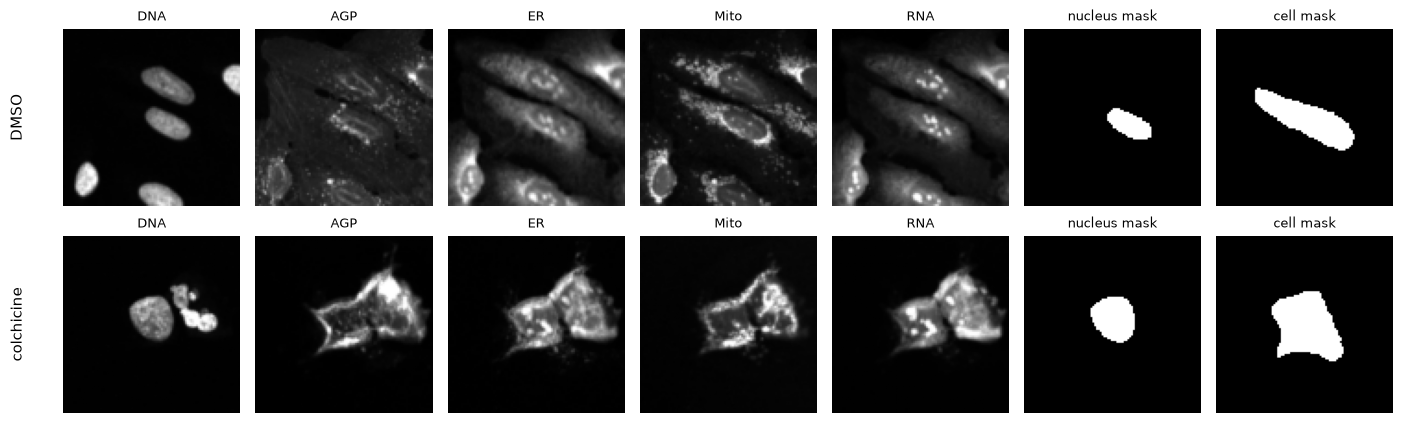

In [9]:
def show_cell(i, axes):
    img, msk = np.asarray(images[i]), np.asarray(masks[i])
    for c, ax in enumerate(axes[:5]):
        ax.imshow(img[c], cmap="gray")
        ax.set_title(cells.uns["image_channels"][c], fontsize=9)
    for m, ax in enumerate(axes[5:]):
        ax.imshow(msk[m], cmap="gray")
        ax.set_title(f"{cells.uns['mask_channels'][m]} mask", fontsize=9)
    for ax in axes:
        ax.axis("off")


obs = cells.obs.reset_index(drop=True)
ok = ~obs.qc_fail.to_numpy()
picks = {"DMSO": int(np.flatnonzero(ok & (obs.compound == "DMSO").to_numpy())[0]),
         "colchicine": int(np.flatnonzero(ok & (obs.compound == "colchicine").to_numpy())[0])}
fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
for row, (name, i) in zip(axes, picks.items()):
    show_cell(i, row)
    row[0].text(-0.3, 0.5, name, transform=row[0].transAxes, rotation=90, va="center", fontsize=11)
plt.tight_layout()

In [10]:
features = ["Cells_Area", "Nuclei_Area", "Cells_Eccentricity", "Cells_FormFactor",
            "Cells_Intensity_MeanIntensity__AGP", "Cells_Intensity_MeanIntensity__Mito"]
features = [f for f in features if f in cells.var_names]
cols = cells.var_names.get_indexer(features)
pd.DataFrame({name: cells.X[i, cols] for name, i in picks.items()}, index=features).round(2)

,DMSO,colchicine
Cells_Area,0.60,1.76
Nuclei_Area,-0.31,2.63
Cells_Eccentricity,0.98,-1.67
Cells_FormFactor,-1.35,-0.13
Cells_Intensity_MeanIntensity__AGP,-0.35,-0.14
Cells_Intensity_MeanIntensity__Mito,1.75,0.61


The numbers are z-scores on each cell's plate. The colchicine cell has a larger area and a rounder shape
(higher form factor, lower eccentricity) than the DMSO cell, matching what we see in the images.

## From cells to wells

Image-based profiling usually works with one profile per **well**: the median of all cells in that well. mantispy
does this with `tl.aggregate`.

In [11]:
wells = mt.tl.aggregate(cells[:, sel].copy(), by=("Metadata_Plate", "Metadata_Well"), func="median", min_cells=5)
print(wells)
wells.obs[["Metadata_Plate", "Metadata_Well", "Metadata_CellCount"]].head()

AnnData object with n_obs × n_vars = 815 × 1144
    obs: 'Metadata_Plate', 'Metadata_Well', 'Metadata_CellCount', 'Metadata_SiteCount', 'Metadata_Source', 'Metadata_Batch', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Compound', 'Metadata_InChIKey', 'Metadata_PlateType', 'compound', 'target', 'is_control', 'activity_class_selection', 'activity_class', 'selection_map', 'highlight', 'source', 'plate', 'well', 'Metadata_ObjectType', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Row', 'Metadata_Col', 'qc_tiny_nucleus'
    var: 'object', 'feature_group', 'feature', 'channel', 'scale', 'angle', 'gray_levels', 'radial_bin', 'params', 'is_feature', 'feature_kind', 'degenerate_scale', 'selected'
    uns: 'mantispy'
    layers: None (.X)


,Metadata_Plate,Metadata_Well,Metadata_CellCount
0,110000293081,B02,19
1,110000293081,C02,12
2,110000293081,C08,13
3,110000293081,E10,10
4,110000293081,F08,12


Aggregating throws away the differences between cells in a well: cells in different phases of the cell cycle,
cells that respond and cells that do not. Deep learning models need many examples to learn from, and a few hundred
wells are not enough, while tens of thousands of single cells are. That is why the single-cell table, with one row
per cell and the crops alongside, is the starting point for the rest of the workshop.

## A map of all cells

To see which cells look alike, we build a **neighbor graph** (each cell connected to the 15 cells with the most
similar features) and draw it in two dimensions with **UMAP**. Cells that are close in the plot have similar
features.

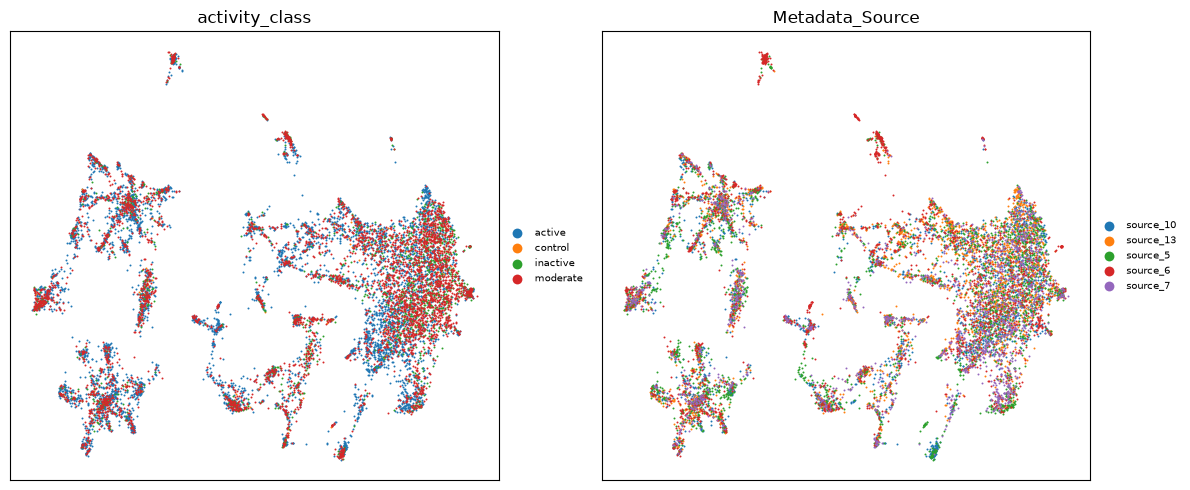

In [12]:
xy = umap_2d(X)  # PCA to 50 dimensions, then UMAP on the 15-nearest-neighbor graph
plot_2d(xy, cells.obs, ["activity_class", "Metadata_Source"])
plt.tight_layout()

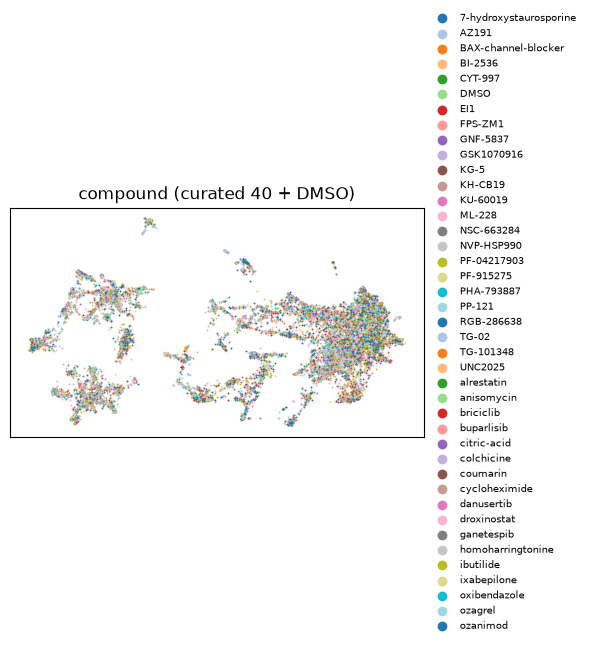

In [13]:
plot_2d(xy, cells.obs, ["highlight"], titles=["compound (curated 40 + DMSO)"], max_legend=45)
plt.tight_layout()

Two things stand out. Cells treated with strongly active compounds (for example the microtubule and translation
inhibitors) move away from the DMSO cells. And cells also group by source: the same compound looks a little
different in each lab. This **batch effect** comes back in notebook 4.

In [14]:
print(f"runtime {time.time() - t_start:.0f} s, peak memory {peak_memory_gb():.2f} GB")

runtime 63 s, peak memory 1.01 GB
